<div align="center">
<h1>Akurasi per Negara Sumber (China, Japan, India)</h1>
<p>YOLOv8n diuji per subset negara pada test N-RDD2024 untuk melihat apakah satu negara menyeret skor gabungan, lalu disandingkan dengan distribusi train.</p>
</div>

In [1]:
import shutil
from pathlib import Path
from collections import Counter

REPO = next((q for q in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (q / 'runs').exists()), Path.cwd().resolve())
SRC = REPO / 'data/NRDD-2024/RDD_Split_Final_china_japan_india_6_classes/RDD_Split_Final_china_japan_india_6_classes'
NAMES = ['Longitudinal_Crack', 'Transverse_Crack', 'Alligator_Crack', 'Pothole', 'manhole', 'patchy_road']
B = REPO / 'runs/rdd_yolov8n_local/per_country'
if B.exists():
    shutil.rmtree(B)
for cty in ['China', 'Japan', 'India']:
    d = B / cty
    (d / 'images').mkdir(parents=True)
    (d / 'labels').mkdir(parents=True)
    for img in (SRC / 'test/images').glob(f'{cty}_*'):
        (d / 'images' / img.name).symlink_to(img.resolve())
        lf = SRC / 'test/labels' / (img.stem + '.txt')
        if lf.exists():
            (d / 'labels' / lf.name).symlink_to(lf.resolve())
    (d / 'c.yaml').write_text(f'path: {d}\ntrain: images\nval: images\ntest: images\nnc: 6\nnames: {NAMES}\n')
    n_img = len(list((d / 'images').iterdir()))
    n_inst = sum(1 for _ in (d / 'labels').glob('*.txt'))
    print(f'{cty}: {n_img} images')


China: 180 images


Japan: 705 images
India: 110 images


## ***Evaluasi per Negara***
---
Val YOLOv8n (conf=0.001, iou=0.6, sama seperti Skenario 1) pada tiap subset negara.

In [2]:
import sys, torch
sys.path.insert(0, str(REPO / 'code/models'))
from ultralytics import YOLO

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
_PATCHED = False
W8 = {
    'yolov8n': 'runs/rdd_yolov8n_local/experiments/yolov8n_class_weight/weights/best.pt',
    'yolov12n': 'runs/rdd_yolov8n_local/experiments/yolov12n_class_weight/weights/best.pt',
    'yolov26n': 'runs/rdd_yolov8n_local/experiments/yolov26n_class_weight/weights/best.pt',
    'yolov8_pd': 'runs/rdd_yolov8n_local/experiments/yolov8_pd_class_weight/weights/best.pt',
    'yolo_rd': 'runs/rdd_yolov8n_local/experiments/yolo_rd_class_weight/weights/best.pt',
}
SRC_TEST = {'yolov8n': 0.648, 'yolov12n': 0.654, 'yolov26n': 0.625, 'yolov8_pd': 0.646, 'yolo_rd': 0.661}
RES = {}
for name, wp in W8.items():
    if name in ('yolov8_pd', 'yolo_rd') and not _PATCHED:
        from custom_modules import patch_ultralytics
        patch_ultralytics()
        _PATCHED = True
    m = YOLO(str(REPO / wp))
    RES[name] = {}
    for cty in ['China', 'Japan', 'India']:
        r = m.val(data=str(B / cty / 'c.yaml'), split='test', imgsz=640, conf=0.001, iou=0.6, verbose=False, device=DEVICE, save_json=False, plots=False)
        per = {int(k): round(float(v), 3) for k, v in zip(r.box.ap_class_index, r.box.ap50)}
        RES[name][cty] = {'mAP50': round(float(r.box.map50), 3), 'per': {i: per.get(i) for i in range(6)}}
        print(f"{name}/{cty}: mAP50={RES[name][cty]['mAP50']} per={list(RES[name][cty]['per'].values())}")


Ultralytics 8.4.115 🚀 Python-3.12.14 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)


Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 114.8±35.3 MB/s, size: 91.5 KB)


val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/per_country/China/labels... 179 images, 0 backgrounds, 0 corrupt: 99% ━━━━━━━━━━━╸ 179/180 535.4it/s 0.1s<0.0s

val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/per_country/China/labels... 180 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 1.8Kit/s 0.1s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 85% ━━━━━━━━━━── 6/7 4.9it/s 1.2s<0.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 5.2it/s 1.3s

                   all        110        233      0.439      0.469      0.442      0.262


Speed: 0.5ms preprocess, 9.6ms inference, 0.0ms loss, 0.4ms postprocess per image


yolo_rd/India: mAP50=0.442 per=[0.184, 0.214, 0.494, 0.325, 0.995, None]


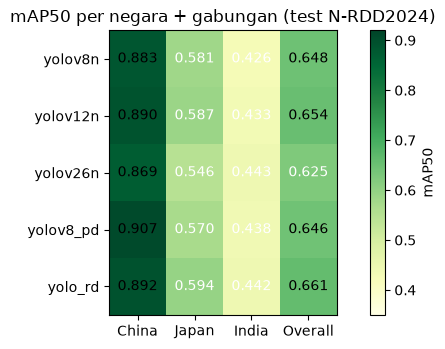

In [3]:
import matplotlib.pyplot as plt
import numpy as np

models = ['yolov8n', 'yolov12n', 'yolov26n', 'yolov8_pd', 'yolo_rd']
cols = ['China', 'Japan', 'India', 'Overall']
M = np.array([[RES[m][c]['mAP50'] if c != 'Overall' else SRC_TEST[m] for c in cols] for m in models])
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(M, vmin=0.35, vmax=0.92, cmap='YlGn')
ax.set_xticks(range(4), cols)
ax.set_yticks(range(5), models)
for i in range(5):
    for j in range(4):
        ax.text(j, i, f'{M[i, j]:.3f}', ha='center', va='center', fontsize=10, color='white' if M[i, j] < 0.63 else 'black')
ax.set_title('mAP50 per negara + gabungan (test N-RDD2024)')
fig.colorbar(im, ax=ax, label='mAP50')
plt.tight_layout()
plt.savefig(str(B / 'per_country_heatmap.png'), dpi=150)
plt.show()


## ***Distribusi Train vs Akurasi***
---
Apakah volume data train menjelaskan peringkat akurasi antarnegara?

In [4]:
import pandas as pd

rows = []
for split in ['train', 'test']:
    img_c, inst = Counter(), Counter()
    for img in (SRC / split / 'images').iterdir():
        c = img.name.split('_')[0]
        img_c[c] += 1
        lf = SRC / split / 'labels' / (img.stem + '.txt')
        if lf.exists():
            for l in lf.read_text().splitlines():
                if l.strip():
                    inst[(c, int(l.split()[0]))] += 1
    for c in ['China', 'Japan', 'India']:
        r = {'split': split, 'negara': c, 'citra': img_c[c]}
        for i, n in enumerate(NAMES):
            r[n] = inst[(c, i)]
        r['total'] = sum(inst[(c, i)] for i in range(6))
        rows.append(r)
df = pd.DataFrame(rows)
print(df.to_string(index=False))


split negara  citra  Longitudinal_Crack  Transverse_Crack  Alligator_Crack  Pothole  manhole  patchy_road  total
train  China   1423                1942               815              460      191      123          208   3739
train  Japan   4624                2250              2385             3449     1270     2139          260  11753
train  India    730                 363                19              476      731        8            3   1600
 test  China    180                 231                91               62       13       12           18    427
 test  Japan    705                 357               349              504      196      308           51   1765
 test  India    110                  47                 6               76      103        1            0    233


## ***Kesimpulan Sementara***
---
- China terbaik (0.883), India terburuk (0.426), Japan tengah (0.581) — padahal Japan 3x lipat data train China. Volume bukan penjelas; kesulitan domain yang menjelaskan.
- Tautan representasi terbersih: Transverse India (train 19 instance -> test 0.038); manhole/patchy India praktis tak terwakili (8/3).
- Caveat: N kecil (India 110 citra; manhole India n=1, patchy n=0) sehingga sel tersebut tidak bisa diklaim.